# 04b · Set 2b data: add chain-of-thought answers to the Set 1 results table (GPU, ~20–30 min on A100)

Copies the Set 1 table's inputs (the **same 400 questions, the same retrievals, the same plain answers**) into a new run folder and
adds answers written **with chain-of-thought (CoT)**: the answer prompt asks the model to write out the first-hop fact, then the second,
then the short `Answer:` line (up to 512 tokens instead of 384). Everything else is unchanged: 5 samples, the same fuser, the same scoring.

CoT is added on the **1-sample retrievals** only, for both answer models, so the table grows from 16 to **24 setups**:
`S1-Sc1, S1-Sc5, S1-Lc1, S1-Lc5, L1-Sc1, L1-Sc5, L1-Lc1, L1-Lc5` (`c` = chain-of-thought).
The Set 1 run folder is only read, never written. The last cell checks that the 16 Set 1 setups come out identical.

Output: `runs/env_qwen_hotpotqa_cot/<timestamp>_<GPU>/` (same layout as notebook 04). Used by notebook 05 with `ALLOW_COT = True` and by notebook 07.

**Runtime → Change runtime type → A100 GPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
STEP0_EXPERIMENT = "env_qwen_hotpotqa"   # Set 1 results tables live here
STEP0_RUN_DIR = ""                       # empty = latest finished Set 1 table (20260928-155333_A100); or paste it
EXPERIMENT  = "env_qwen_hotpotqa_cot"
LARGE_MODEL_DIR = "Qwen2.5-7B-Instruct"
TIME_LIMIT_MIN = 55          # every stage stops cleanly at this limit and keeps what is done
RESUME_RUN_DIR = None        # an interrupted run folder, to continue it
DRY_RUN = False              # True = fake models on CPU, tests the whole notebook in ~1 min

In [2]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import glob
if not STEP0_RUN_DIR:   # empty = the latest finished results-table run in runs/<STEP0_EXPERIMENT> (dry runs skipped)
    done = [p for p in sorted(glob.glob(f"{PROJECT_DIR}/runs/{STEP0_EXPERIMENT}/*/table/per_question.csv")) if "_dryrun" not in p or DRY_RUN]
    assert done, f"No finished results table in runs/{STEP0_EXPERIMENT} - run notebook {'04b' if 'cot' in STEP0_EXPERIMENT else '04'} first."
    STEP0_RUN_DIR = os.path.dirname(os.path.dirname(done[-1]))
assert os.path.exists(f"{STEP0_RUN_DIR}/table/per_question.csv"), f"{STEP0_RUN_DIR} is not a finished results-table run."
print("Results table:", STEP0_RUN_DIR)
DATA_DIR = json.load(open(f"{STEP0_RUN_DIR}/config.json"))["data_dir"]
SET1_DIR = STEP0_RUN_DIR
for f in ["retrieval_S", "retrieval_L", "answers_S", "answers_L", "answer_samples_S", "answer_samples_L"]:
    assert os.path.exists(f"{SET1_DIR}/step0/{f}.jsonl"), f"{SET1_DIR}/step0/{f}.jsonl missing"

Results table: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/env_qwen_hotpotqa/20260928-155333_A100


In [5]:
from datetime import datetime
from zoneinfo import ZoneInfo
if RESUME_RUN_DIR:
    RUN_DIR = RESUME_RUN_DIR
else:
    stamp = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
    RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{stamp}_{GPU_TAG}" + ("_dryrun" if DRY_RUN else "")
for sub in ["logs", "code"]:
    os.makedirs(f"{RUN_DIR}/{sub}", exist_ok=True)
print("Run folder:", RUN_DIR)
# copy (never move) the Set 1 inputs; on resume, files already here are kept
os.makedirs(f"{RUN_DIR}/step0", exist_ok=True)
os.makedirs(f"{RUN_DIR}/stages", exist_ok=True)
for f in os.listdir(f"{SET1_DIR}/step0"):
    if not os.path.exists(f"{RUN_DIR}/step0/{f}"):
        shutil.copy(f"{SET1_DIR}/step0/{f}", f"{RUN_DIR}/step0/{f}")
for f in os.listdir(f"{SET1_DIR}/stages"):
    if not os.path.exists(f"{RUN_DIR}/stages/{f}"):
        shutil.copy(f"{SET1_DIR}/stages/{f}", f"{RUN_DIR}/stages/{f}")
print("copied Set 1 retrievals, plain answers and stage timings from", SET1_DIR)
if not os.path.exists(f"{RUN_DIR}/config.json"):
    json.dump({"experiment": EXPERIMENT, "set": "2b-data", "source_set1_run": SET1_DIR, "data_dir": DATA_DIR,
               "large_model_dir": LARGE_MODEL_DIR, "gpu": gpu, "cot_answer_max_tokens": 512, "dry_run": DRY_RUN,
               "started": datetime.now(ZoneInfo("Asia/Singapore")).isoformat()}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

Run folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/env_qwen_hotpotqa_cot/20260929-140148_A100
copied Set 1 retrievals, plain answers and stage timings from /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/env_qwen_hotpotqa/20260928-155333_A100


In [6]:
BACKEND = "mock" if DRY_RUN else "vllm"
CODE = "/content/ssw.py"
shutil.copy(f"{PROJECT_DIR}/code/ssw.py", CODE)
shutil.copy(CODE, f"{RUN_DIR}/code/ssw.py")          # keep the exact code with the results

def minutes_left():
    return max(1.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name):
    """Runs one ssw.py command in a fresh process; streams output here and into logs/<log_name>."""
    cmd = [sys.executable, "-u", CODE] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log:
        log.write("\n$ " + " ".join(cmd) + "\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line)
            if any(k in line for k in ("it/s]", "s/it]", "INFO ", "(EngineCore")):
                continue                      # keep the notebook readable; everything is in the log file
            print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = round(time.time() - t0)
    json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
    print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    if p.returncode != 0:
        raise RuntimeError(f"stage failed - see {RUN_DIR}/logs/{log_name}")
TIMES = {}

In [7]:
# vLLM runs only inside the stage processes, so no runtime restart is needed (~3-5 min)
if not DRY_RUN:
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
TIMES["install_vllm"] = round(time.time() - T_START)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.9/314.9 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 96.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.7/322.7 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

In [8]:
LOCAL = "/content/models"
MODELS = {
    "S": {"id": "Qwen/Qwen2.5-3B-Instruct", "dir": "Qwen2.5-3B-Instruct", "params": 3.09e9, "nominal": 3e9},
    "L": {"id": "Qwen/Qwen2.5-7B-Instruct", "dir": LARGE_MODEL_DIR,       "params": 7.62e9, "nominal": 7e9},
}
_t = time.time()
for key in ["S", "L"]:
    m = MODELS[key] if key in MODELS else {"dir": key}
    src, dst = f"{PROJECT_DIR}/models/{m['dir']}", f"{LOCAL}/{m['dir']}"
    m["path"] = dst
    if DRY_RUN:
        continue
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run 00_setup_download_qwen7b first."
    if not os.path.exists(f"{dst}/config.json"):
        print("copying", m["dir"], "to local disk ...")
        shutil.copytree(src, dst, dirs_exist_ok=True)
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
TIMES["copy_models"] = round(time.time() - _t)
print(f"models ready in {time.time() - _t:.0f}s")

copying Qwen2.5-3B-Instruct to local disk ...
copying Qwen2.5-7B-Instruct to local disk ...
models ready in 377s


### Chain-of-thought answers (5 samples) + fuse, with 7B then 3B, on both retrievers' 1-sample selections

In [9]:
COMMON = ["--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json", "--backend", BACKEND]
for k in ["L", "S"]:
    run_stage(["answer", "--cot", "--model_key", k, "--time_limit_min", minutes_left()] + COMMON, f"02_answer_{k}c.log")

[06:11:54] answer (chain-of-thought) | Qwen/Qwen2.5-7B-Instruct | retrievers ['L', 'S'] | 400 questions (0 done) | 5 answer samples + fusion
[06:15:44]   20/400 | answer prompts 33, fuser prompts 66
[06:15:54]   40/400 | answer prompts 35, fuser prompts 70
[06:16:03]   60/400 | answer prompts 39, fuser prompts 78
[06:16:13]   80/400 | answer prompts 35, fuser prompts 70
[06:16:22]   100/400 | answer prompts 36, fuser prompts 72
[06:16:30]   120/400 | answer prompts 35, fuser prompts 70
[06:16:40]   140/400 | answer prompts 35, fuser prompts 70
[06:16:48]   160/400 | answer prompts 34, fuser prompts 68
[06:17:02]   180/400 | answer prompts 37, fuser prompts 74
[06:17:12]   200/400 | answer prompts 36, fuser prompts 72
[06:17:24]   220/400 | answer prompts 37, fuser prompts 74
[06:17:33]   240/400 | answer prompts 36, fuser prompts 72
[06:17:41]   260/400 | answer prompts 37, fuser prompts 74
[06:17:51]   280/400 | answer prompts 36, fuser prompts 72
[06:17:59]   300/400 | answer prompts

### 24-setup table

In [10]:
run_stage(["table", "--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json"], "03_table.log")
print("\nResults table for notebooks 05 (ALLOW_COT = True) and 07:\n", RUN_DIR)

# Step 0 summary - 20260929-140148_A100

GPU: NVIDIA A100-SXM4-40GB, 8.0 · configs: 24 · questions: {'dev': 200, 'test': 200}

Measured lengths used for Eq. 4: retrieval Np=2748, Nd=150; QA Np=351, Nd=22; CoT QA Np=393, Nd=135


## dev: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L1-Lc5 | retrieval 7B x1, answer 7B CoT x5 | 0.495 | 0.643 | 0.736 | 70.2 | 0.75 | 141 |
| L1-Lc1 | retrieval 7B x1, answer 7B CoT x1 | 0.485 | 0.622 | 0.736 | 58.3 | 0.63 | 121 |
| L1-Sc1 | retrieval 7B x1, answer 3B CoT x1 | 0.475 | 0.587 | 0.736 | 51.6 | 0.60 | 110 |
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.460 | 0.597 | 0.729 | 63.7 | 0.71 | 129 |
| L1-Sc5 | retrieval 7B x1, answer 3B CoT x5 | 0.455 | 0.592 | 0.736 | 59.6 | 0.71 | 118 |
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.455 | 0.591 | 0.736 | 57.6 | 0.64 | 118 |
| S1-Lc5 | retrieval 3B x1, answer 7B CoT x5 | 0.415 | 0.538 | 0.520 | 43.6 |

### Check: the 16 Set 1 setups must be unchanged

In [11]:
import pandas as pd
a = pd.read_csv(f"{SET1_DIR}/table/per_question.csv")
b = pd.read_csv(f"{RUN_DIR}/table/per_question.csv")
m = a.merge(b, on=["qid", "config"], suffixes=("_set1", "_new"))
diff = {c: float((m[c + "_set1"] - m[c + "_new"]).abs().max()) for c in ["EM", "F1", "flops", "est_gpu_s", "budget_eq4"]}
print(f"setups: Set 1 {a.config.nunique()}, now {b.config.nunique()} | matched rows {len(m)} of {len(a)} | max differences {diff}")
print("OK - Set 1 setups unchanged" if len(m) == len(a) and max(diff.values()) < 1e-9 else "WARNING - Set 1 setups changed, check before using this table")
cot = b[b.ans_model.str.endswith("c")]
print(f"CoT answers: mean {cot.ans_output_tokens.div(cot.ans_k).mean():.0f} output tokens per sample "
      f"(plain: {b[~b.ans_model.str.endswith('c')].ans_output_tokens.div(b.ans_k).mean():.0f})")
json.dump({"set1_rows_matched": int(len(m)), "set1_rows": int(len(a)), "max_diff": diff},
          open(f"{RUN_DIR}/table/set1_check.json", "w"), indent=1)

setups: Set 1 16, now 24 | matched rows 6400 of 6400 | max differences {'EM': 0.0, 'F1': 0.0, 'flops': 0.0, 'est_gpu_s': 0.0, 'budget_eq4': 0.0}
OK - Set 1 setups unchanged
CoT answers: mean 135 output tokens per sample (plain: 22)


# Step 0 summary - 20260929-140148_A100

GPU: NVIDIA A100-SXM4-40GB, 8.0 · configs: 24 · questions: {'dev': 200, 'test': 200}

Measured lengths used for Eq. 4: retrieval Np=2748, Nd=150; QA Np=351, Nd=22; CoT QA Np=393, Nd=135


## dev: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L1-Lc5 | retrieval 7B x1, answer 7B CoT x5 | 0.495 | 0.643 | 0.736 | 70.2 | 0.75 | 141 |
| L1-Lc1 | retrieval 7B x1, answer 7B CoT x1 | 0.485 | 0.622 | 0.736 | 58.3 | 0.63 | 121 |
| L1-Sc1 | retrieval 7B x1, answer 3B CoT x1 | 0.475 | 0.587 | 0.736 | 51.6 | 0.60 | 110 |
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.460 | 0.597 | 0.729 | 63.7 | 0.71 | 129 |
| L1-Sc5 | retrieval 7B x1, answer 3B CoT x5 | 0.455 | 0.592 | 0.736 | 59.6 | 0.71 | 118 |
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.455 | 0.591 | 0.736 | 57.6 | 0.64 | 118 |
| S1-Lc5 | retrieval 3B x1, answer 7B CoT x5 | 0.415 | 0.538 | 0.520 | 43.6 | 0.53 | 80 |
| L3-L1 | retrieval 7B x3, answer 7B x1 | 0.395 | 0.497 | 0.729 | 61.6 | 0.69 | 126 |
| L1-L1 | retrieval 7B x1, answer 7B x1 | 0.390 | 0.494 | 0.736 | 55.6 | 0.62 | 115 |
| S1-Lc1 | retrieval 3B x1, answer 7B CoT x1 | 0.380 | 0.502 | 0.520 | 31.4 | 0.41 | 61 |
| S1-L5 | retrieval 3B x1, answer 7B x5 | 0.370 | 0.493 | 0.520 | 31.6 | 0.43 | 58 |
| L1-S5 | retrieval 7B x1, answer 3B x5 | 0.370 | 0.494 | 0.736 | 49.8 | 0.60 | 109 |
| S3-L5 | retrieval 3B x3, answer 7B x5 | 0.370 | 0.478 | 0.512 | 32.9 | 0.45 | 63 |
| L3-S5 | retrieval 7B x3, answer 3B x5 | 0.370 | 0.497 | 0.729 | 55.8 | 0.66 | 120 |
| S1-Sc5 | retrieval 3B x1, answer 3B CoT x5 | 0.345 | 0.446 | 0.520 | 33.0 | 0.50 | 58 |
| S3-L1 | retrieval 3B x3, answer 7B x1 | 0.340 | 0.423 | 0.512 | 29.9 | 0.42 | 60 |
| S1-L1 | retrieval 3B x1, answer 7B x1 | 0.335 | 0.426 | 0.520 | 28.6 | 0.40 | 55 |
| S1-Sc1 | retrieval 3B x1, answer 3B CoT x1 | 0.315 | 0.426 | 0.520 | 24.6 | 0.38 | 50 |
| S3-S5 | retrieval 3B x3, answer 3B x5 | 0.300 | 0.394 | 0.512 | 24.5 | 0.40 | 53 |
| L3-S1 | retrieval 7B x3, answer 3B x1 | 0.280 | 0.364 | 0.729 | 55.0 | 0.65 | 118 |
| S1-S5 | retrieval 3B x1, answer 3B x5 | 0.280 | 0.398 | 0.520 | 23.2 | 0.38 | 48 |
| L1-S1 | retrieval 7B x1, answer 3B x1 | 0.275 | 0.355 | 0.736 | 49.1 | 0.58 | 107 |
| S3-S1 | retrieval 3B x3, answer 3B x1 | 0.225 | 0.287 | 0.512 | 23.4 | 0.38 | 52 |
| S1-S1 | retrieval 3B x1, answer 3B x1 | 0.210 | 0.282 | 0.520 | 22.1 | 0.36 | 47 |

**Oracle router (dev):** EM 0.675 at 28.0 TFLOPs/q · best single config L1-Lc5: EM 0.495 at 70.2 TFLOPs/q · cheapest S1-S1: EM 0.210 at 22.1 TFLOPs/q

Questions only a config using the 7B gets right: 47 of 200 · only all-3B gets right: 2

**Go/no-go:** on dev the oracle router is +0.180 EM vs the best single config, at 60% less compute. There is room for per-question switching - go ahead with per-question switching.

## test: configurations (mean per question)

| config | meaning | EM | F1 | Ret_F1 | TFLOPs/q | est. GPU s/q | Eq.4 budget |
|---|---|---|---|---|---|---|---|
| L1-Lc5 | retrieval 7B x1, answer 7B CoT x5 | 0.550 | 0.667 | 0.708 | 70.6 | 0.75 | 141 |
| L1-L5 | retrieval 7B x1, answer 7B x5 | 0.545 | 0.660 | 0.708 | 58.4 | 0.65 | 118 |
| L3-L5 | retrieval 7B x3, answer 7B x5 | 0.545 | 0.659 | 0.720 | 64.1 | 0.71 | 129 |
| L1-Sc5 | retrieval 7B x1, answer 3B CoT x5 | 0.520 | 0.624 | 0.708 | 59.9 | 0.72 | 118 |
| L1-Lc1 | retrieval 7B x1, answer 7B CoT x1 | 0.515 | 0.640 | 0.708 | 58.8 | 0.64 | 121 |
| L1-Sc1 | retrieval 7B x1, answer 3B CoT x1 | 0.505 | 0.616 | 0.708 | 52.0 | 0.61 | 110 |
| L1-L1 | retrieval 7B x1, answer 7B x1 | 0.470 | 0.563 | 0.708 | 56.1 | 0.62 | 115 |
| L3-L1 | retrieval 7B x3, answer 7B x1 | 0.465 | 0.554 | 0.720 | 62.0 | 0.69 | 126 |
| S1-Lc5 | retrieval 3B x1, answer 7B CoT x5 | 0.440 | 0.542 | 0.498 | 43.8 | 0.53 | 80 |
| S3-L5 | retrieval 3B x3, answer 7B x5 | 0.440 | 0.531 | 0.502 | 33.2 | 0.45 | 63 |
| S1-L5 | retrieval 3B x1, answer 7B x5 | 0.420 | 0.514 | 0.498 | 32.1 | 0.43 | 58 |
| S3-L1 | retrieval 3B x3, answer 7B x1 | 0.405 | 0.481 | 0.502 | 29.9 | 0.42 | 60 |
| L3-S5 | retrieval 7B x3, answer 3B x5 | 0.400 | 0.518 | 0.720 | 56.3 | 0.67 | 120 |
| L1-S5 | retrieval 7B x1, answer 3B x5 | 0.400 | 0.524 | 0.708 | 50.5 | 0.61 | 109 |
| S1-L1 | retrieval 3B x1, answer 7B x1 | 0.395 | 0.480 | 0.498 | 28.7 | 0.40 | 55 |
| S1-Lc1 | retrieval 3B x1, answer 7B CoT x1 | 0.385 | 0.488 | 0.498 | 31.3 | 0.41 | 61 |
| S1-Sc1 | retrieval 3B x1, answer 3B CoT x1 | 0.370 | 0.467 | 0.498 | 24.8 | 0.39 | 50 |
| S1-Sc5 | retrieval 3B x1, answer 3B CoT x5 | 0.370 | 0.476 | 0.498 | 33.2 | 0.50 | 58 |
| L1-S1 | retrieval 7B x1, answer 3B x1 | 0.345 | 0.447 | 0.708 | 49.6 | 0.59 | 107 |
| L3-S1 | retrieval 7B x3, answer 3B x1 | 0.335 | 0.439 | 0.720 | 55.5 | 0.66 | 118 |
| S3-S5 | retrieval 3B x3, answer 3B x5 | 0.300 | 0.416 | 0.502 | 24.6 | 0.40 | 53 |
| S1-S5 | retrieval 3B x1, answer 3B x5 | 0.270 | 0.387 | 0.498 | 23.4 | 0.38 | 48 |
| S3-S1 | retrieval 3B x3, answer 3B x1 | 0.270 | 0.345 | 0.502 | 23.5 | 0.39 | 52 |
| S1-S1 | retrieval 3B x1, answer 3B x1 | 0.250 | 0.337 | 0.498 | 22.2 | 0.36 | 47 |

**Oracle router (test):** EM 0.720 at 28.4 TFLOPs/q · best single config L1-Lc5: EM 0.550 at 70.6 TFLOPs/q · cheapest S1-S1: EM 0.250 at 22.2 TFLOPs/q

Questions only a config using the 7B gets right: 47 of 200 · only all-3B gets right: 3


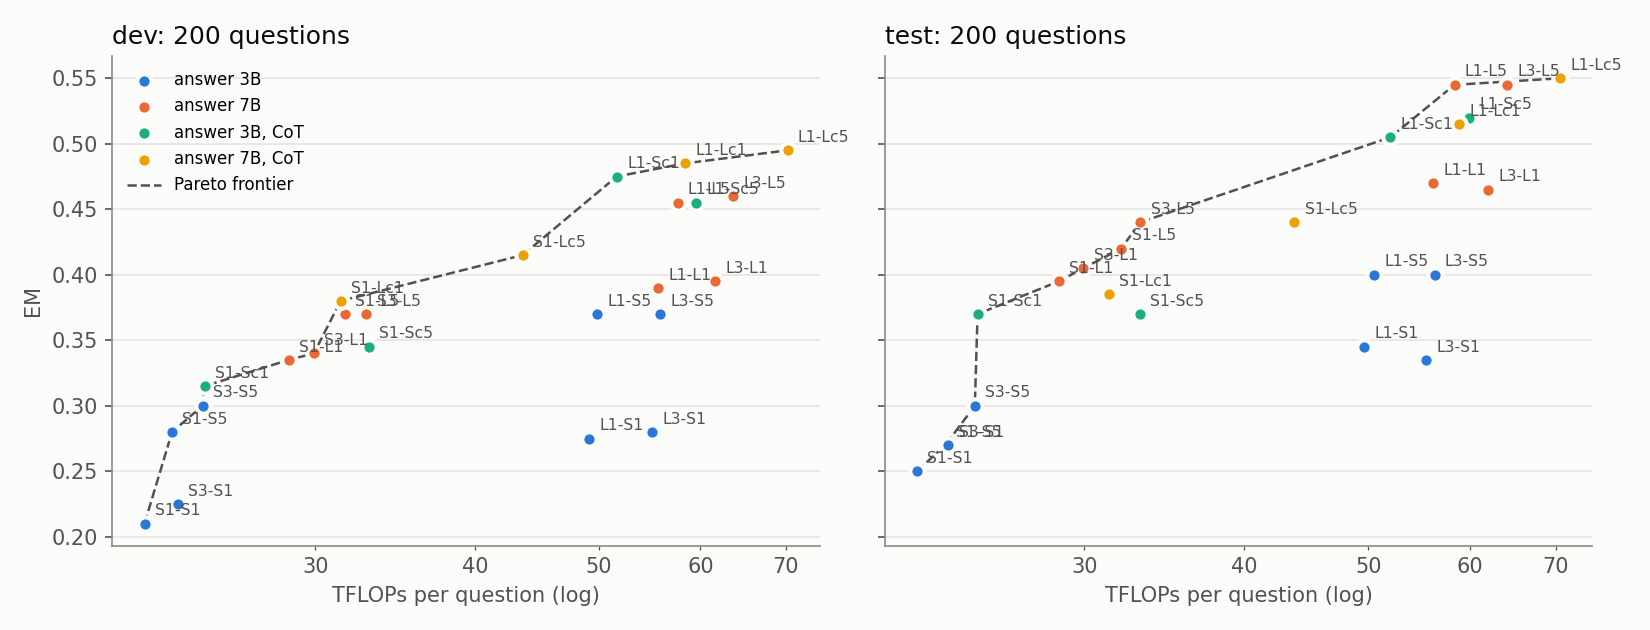

Wall-clock (s): {'install_vllm': 253, 'copy_models': 377, '02_answer_Lc': 419, '02_answer_Sc': 274, '03_table': 3, 'total_notebook': 1327}


In [12]:
from IPython.display import Image, Markdown, display
for f in ["table/summary.md", "table/configs_em_vs_flops.png"]:
    p = f"{RUN_DIR}/{f}"
    if not os.path.exists(p):
        continue
    display(Markdown(open(p).read()) if p.endswith(".md") else Image(p))
TIMES["total_notebook"] = round(time.time() - T_START)
json.dump(TIMES, open(f"{RUN_DIR}/logs/stage_times.json", "w"), indent=1)
print("Wall-clock (s):", TIMES)